# e34: transferability suite on Norway (2026-10-16)

Train on a coarse sample of the Norway DEM, test on the stride-4 grid of the same terrain
(`full_test-004.npz`: 250k nodes, 10 sources × 250k targets). Design and results: `docs/2026-10-e34-transfer-suite.md`.

| Item | Value |
| --- | --- |
| Models | MLP on xyz, TAGConv K=3, SparseGT k=2 (RPEARL data mode), SparseGT k=2 with Laplacian eigenvectors (LapPE, e35, k=64); siamese L1 head |
| Schemes | grid, uniform, Poisson-disk, slope-adaptive, quadtree |
| Training strides | 32, 24, 16, 12, 8, 4 (3,969 to 250,000 nodes) |
| Recipe | e32: batch 8192, AdamW wd 0.1, warmup 300, constant lr; SparseGT 200 epochs, others 100 |

Sections:
1. Transferability curves, one panel per scheme.
2. Three sample paths per model, for models trained on the smallest grid (stride 32) and the largest (stride 4).
3. Error heatmaps on the test terrain for one hard source, and whether the rays are a straight-line bias (3.1).
4. Cost of the Laplacian eigenvectors (e35), which RPEARL does not pay.

The LapPE runs (`sgt2lap`) come from `$E35_RUNS` (doc section 7); the other three models from `$E34_RUNS`.

Section 2 and 3 run on the test terrain. A model predicts distances only. I draw its path by greedy descent:
from node $i$, step to the unvisited neighbour $j$ that minimises $w_{ij} + \hat d(j, t)$.
The path is the route the model's distance field implies, not a model output.

Cached arrays go to `$E34_RUNS/analysis/cache`, so a rerun without a GPU needs only that folder.

In [1]:
import glob, json, os, re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import dijkstra

RUNS = Path(os.environ.get('E34_RUNS', '~/runs/e34')).expanduser()
E35 = Path(os.environ.get('E35_RUNS', '~/runs/e35/suite')).expanduser()     # the sgt2lap runs (e35)
LAPPE = Path(os.environ.get('SPNN_LAPPE_CACHE', '~/data/spnn/lappe')).expanduser()   # eigenvectors + cost sidecars
DATA = Path(os.environ.get('E34_DATA', '~/data/spnn/e31')).expanduser()
TEST = Path(os.environ.get('E34_TEST', '~/data/spnn/full_test-004.npz')).expanduser()
REPO = Path(os.environ.get('SPNN_REPO', '..')).resolve()
CACHE = RUNS / 'analysis' / 'cache'
FIGS = RUNS / 'analysis' / 'figures'
CACHE.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

SCHEMES = ['grid', 'uniform', 'poisson-disk', 'slope-adaptive', 'quadtree']
SCHEME_TITLES = {'grid': 'Grid', 'uniform': 'Uniform', 'poisson-disk': 'Poisson-disk',
                 'slope-adaptive': 'Slope-adaptive', 'quadtree': 'Quadtree'}
STRIDES = [32, 24, 16, 12, 8, 4]
MODELS = ['mlp', 'tagconv', 'sgt2', 'sgt2lap']
MODEL_NAMES = {'mlp': 'MLP', 'tagconv': 'TAGConv', 'sgt2': 'SparseGT', 'sgt2lap': 'SparseGT+LapPE'}
SHORT = {'mlp': 'MLP', 'tagconv': 'TAG', 'sgt2': 'SGT', 'sgt2lap': 'LapPE'}

# Colours and markers from notebooks/PLOTTING_STYLE.md: TAGConv takes the GNN baseline style,
# SparseGT the Sparse GT colour; MLP takes the first extra colour.
PALETTE = {'mlp': '#e07a5f', 'tagconv': '#7f8c8d', 'sgt2': '#81b29a', 'sgt2lap': '#3d5a80'}
MARKERS = {'mlp': 's', 'tagconv': 'o', 'sgt2': 'v', 'sgt2lap': '^'}
def line_attrs(model, base_lw=1.2, base_ms=3.5):
    if model == 'tagconv':
        return dict(lw=base_lw * 0.55, ms=base_ms * 0.78, alpha=0.78, ls='--', zorder=2)
    if model == 'sgt2lap':
        return dict(lw=base_lw * 0.9, ms=base_ms, alpha=0.95, ls='-.', zorder=4)
    if model == 'sgt2':
        return dict(lw=base_lw * 1.05, ms=base_ms * 1.05, alpha=1.0, ls='-', zorder=5)
    return dict(lw=base_lw, ms=base_ms, alpha=0.95, ls='-', zorder=3)

RC = {'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none', 'axes.unicode_minus': False,
      'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
      'mathtext.fontset': 'stix', 'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
      'axes.titlepad': 4, 'axes.titlelocation': 'left', 'legend.fontsize': 8,
      'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.7}
mpl.rcParams.update(RC)

def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('#444')
    ax.tick_params(colors='#444')

# Reference numbers on the same test set (docs/2026-10-e31-sampling-transfer.md, section 6).
# Chen et al. (ICML 2025) numbers are from their Table 3 on their own test graph, not on full_test-004.
REFS = {'GAT+L1 (Chen stage 1, grid s8)': (0.52, ':'), 'octile+dz×c, no training': (1.12, '-.')}
REFS_ACC2 = {'GAT+L1 (Chen stage 1, grid s8)': (96.5, ':'), 'octile+dz×c, no training': (86.2, '-.'),
             'Chen M-CTR, paper': (91.1, '--')}
REF_TABLE = pd.DataFrame([
    ('Chen, Coarse-GAT+L1 (paper Table 3, own test graph)', 1.05, 89.2),
    ('Chen, M-CTR two-stage (paper Table 3, own test graph)', 0.90, 91.1),
    ('Our replication of Chen stage 1, GAT+L1, grid s8, 500 epochs', 0.52, 96.5),
    ('octile+dz × c, 100 calibration pairs', 1.12, 86.2),
    ('octile+dz, no training', 2.40, 47.1),
], columns=['reference', 'test nmae (%)', 'acc<2% (%)'])

## 1. Transferability curves

In [2]:
rows = []
for f in (sorted(RUNS.glob('norway_*_s??_*.json')) + sorted((RUNS / 'seed1').glob('norway_*_s??_*.json'))
          + sorted(E35.glob('norway_*_s??_sgt2lap.json'))):
    m = re.match(r'norway_(.+)_s(\d\d)_(\w+)\.json', f.name)
    scheme, stride, model = m[1], int(m[2]), m[3]
    seed = 0
    if scheme.endswith('-seed1'):
        scheme, seed = scheme[:-len('-seed1')], 1
    final = json.load(open(f))['final']
    info = json.load(open(DATA / f'norway_{m[1]}_s{m[2]}.json'))
    rows.append(dict(scheme=scheme, stride=stride, model=model, seed=seed, n_nodes=info['n_nodes'],
                     test_nmae=100 * final['test_nmae'], test_acc2=100 * final['test_acc_2pct'],
                     train_nmae=100 * final['final_train_nmae']))
res = pd.DataFrame(rows)
print(f"{len(res[res.seed == 0])} of 120 suite runs ({res[res.seed == 0].groupby('model').size().to_dict()}), "
      f"{len(res[res.seed == 1])} seed-1 runs")
res[res.seed == 0].pivot_table(index=['scheme', 'stride'], columns='model', values='test_nmae') \
    .reindex(columns=MODELS).loc[SCHEMES].round(2)

120 of 120 suite runs ({'mlp': 30, 'sgt2': 30, 'sgt2lap': 30, 'tagconv': 30}), 3 seed-1 runs


model                    mlp  tagconv   sgt2  sgt2lap
scheme         stride                                
grid           4        0.71     0.83   0.62     0.68
               8        0.69     0.77   0.62     0.66
               12       0.69     0.79   0.60     0.70
               16       0.70     0.83   0.65     0.69
               24       0.75     0.97   0.70     0.82
               32       0.83     1.04   0.87     0.83
uniform        4        1.67     1.74   1.63     1.67
               8        1.69     1.73   1.62     1.65
               12       1.76     1.79   1.72     1.70
               16       1.76     1.75   1.66     1.67
               24       1.74     1.83   1.85     1.79
               32       1.81     2.11   2.02     1.87
poisson-disk   4        2.20     2.28   2.25     2.27
               8        2.24     2.41   2.38     2.35
               12       2.23     2.36   2.34     2.33
               16       2.39     2.38   2.38     2.49
               24       2.46     2.41   2.57     2.53
               32       2.52     2.47   2.54     2.60
slope-adaptive 4        1.71     1.69   1.62     1.63
               8        1.76     1.75   1.64     1.68
               12       1.81     1.80   1.71     1.69
               16       1.83     1.79   1.84     1.72
               24       1.98     2.08   2.47     2.24
               32       1.64     1.91   1.98     1.99
quadtree       4       19.98    19.96  19.90    19.78
               8       20.07    20.03  19.92    19.92
               12      20.19    19.99  19.99    19.81
               16      20.20    19.96  20.00    20.10
               24      19.84    19.81  19.79    19.75
               32      19.84    19.94  19.69    19.75

Share of test pairs within 2% of the true distance (acc<2%, Chen's accuracy metric), in %:

In [3]:
res[res.seed == 0].pivot_table(index=['scheme', 'stride'], columns='model', values='test_acc2') \
    .reindex(columns=MODELS).loc[SCHEMES].round(1)

model                   mlp  tagconv  sgt2  sgt2lap
scheme         stride                              
grid           4       93.6     91.5  95.6     94.8
               8       93.6     92.7  95.1     94.6
               12      93.9     92.3  95.7     94.1
               16      93.9     91.3  94.6     94.1
               24      93.1     89.6  94.1     92.9
               32      91.8     88.3  91.2     92.0
uniform        4       67.9     66.7  69.2     67.7
               8       68.1     68.1  70.4     67.8
               12      66.0     66.2  67.0     67.2
               16      66.5     66.7  69.0     68.1
               24      67.1     65.4  64.1     64.7
               32      65.3     59.6  60.9     63.7
poisson-disk   4       47.0     45.3  45.5     44.8
               8       45.7     42.8  42.5     43.2
               12      45.7     43.6  43.2     43.2
               16      42.9     43.5  42.3     40.1
               24      41.1     43.4  38.5     39.2
               32      40.1     42.4  39.1     38.6
slope-adaptive 4       67.5     68.7  70.0     69.4
               8       66.3     66.9  69.9     68.4
               12      64.8     65.1  67.4     67.8
               16      64.0     66.0  65.0     66.6
               24      60.5     59.8  57.1     57.5
               32      70.5     64.5  63.2     63.1
quadtree       4        2.5      2.4   2.8      2.3
               8        2.1      1.7   2.3      1.7
               12       1.5      1.5   1.7      1.7
               16       1.2      1.7   1.7      1.1
               24       2.1      2.5   2.0      2.0
               32       1.9      1.9   2.8      1.7

References. Chen's numbers come from their paper, on their own test graph; the others are on `full_test-004`.

In [4]:
REF_TABLE

,reference,test nmae (%),acc<2% (%)
0,"Chen, Coarse-GAT+L1 (paper Table 3, own test g...",1.05,89.2
1,"Chen, M-CTR two-stage (paper Table 3, own test...",0.90,91.1
2,"Our replication of Chen stage 1, GAT+L1, grid ...",0.52,96.5
3,"octile+dz × c, 100 calibration pairs",1.12,86.2
4,"octile+dz, no training",2.40,47.1


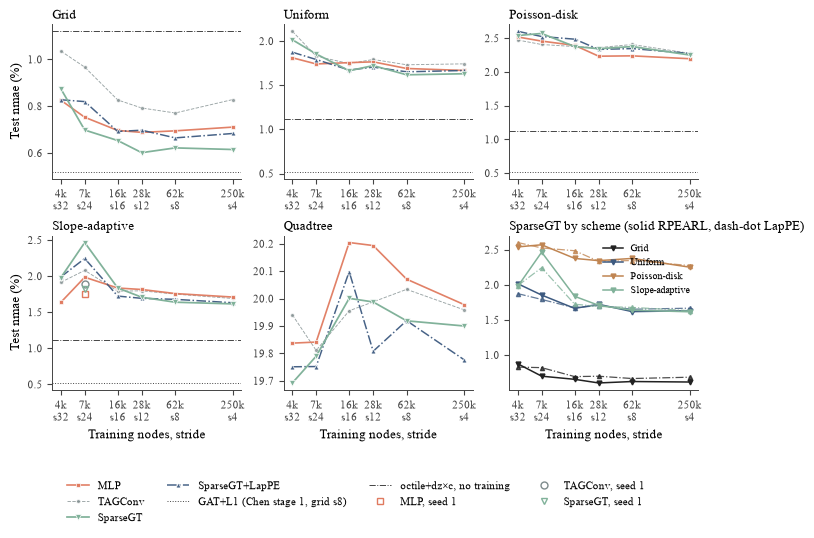

In [5]:
def plot_transfer(metric='test_nmae', ylabel='Test nmae (%)', refs=REFS, fname='e34_transfer_nmae'):
    fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.4), constrained_layout=True)
    ticks = sorted(res[res.scheme == 'grid'].drop_duplicates('stride')[['n_nodes', 'stride']].values.tolist())
    for ax, scheme in zip(axes.ravel(), SCHEMES):
        sub = res[(res.scheme == scheme) & (res.seed == 0)]
        for model in MODELS:
            g = sub[sub.model == model].sort_values('n_nodes')
            ax.plot(g.n_nodes, g[metric], marker=MARKERS[model], color=PALETTE[model], label=MODEL_NAMES[model],
                    markeredgecolor='white', markeredgewidth=0.5, **line_attrs(model))
            s1 = res[(res.scheme == scheme) & (res.seed == 1) & (res.model == model)]
            if len(s1):
                ax.plot(s1.n_nodes, s1[metric], marker=MARKERS[model], ls='none', mfc='none',
                        color=PALETTE[model], ms=5, label=f'{MODEL_NAMES[model]}, seed 1')
        if refs and scheme != 'quadtree':
            for name, (val, ls) in refs.items():
                ax.axhline(val, color='#444', lw=0.7, ls=ls, label=name)
        ax.set_xscale('log')
        ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
        ax.minorticks_off()
        ax.set_title(SCHEME_TITLES[scheme])
        clean_axes(ax)
    # Last panel: SparseGT on every scheme except quadtree, to compare schemes on one axis.
    ax = axes.ravel()[-1]
    for scheme, c in zip(SCHEMES[:-1], ['#222', '#3d5a80', '#c08552', '#81b29a']):
        g = res[(res.scheme == scheme) & (res.model == 'sgt2') & (res.seed == 0)].sort_values('n_nodes')
        ax.plot(g.n_nodes, g[metric], marker='v', color=c, lw=1.1, ms=3.5, label=SCHEME_TITLES[scheme])
        g = res[(res.scheme == scheme) & (res.model == 'sgt2lap') & (res.seed == 0)].sort_values('n_nodes')
        if len(g):   # dash-dot: the same scheme with LapPE instead of RPEARL
            ax.plot(g.n_nodes, g[metric], marker='^', color=c, lw=0.9, ms=3.0, ls='-.', alpha=0.8)
    ax.set_xscale('log'); ax.minorticks_off()
    ax.set_xticks([n for n, _ in ticks], [f'{n/1000:.0f}k\ns{s}' for n, s in ticks])
    ax.set_title('SparseGT by scheme (solid RPEARL, dash-dot LapPE)'); ax.legend(frameon=False, fontsize=7); clean_axes(ax)
    for ax in axes[1, :]:
        ax.set_xlabel('Training nodes, stride')
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    h, l = axes[0, 0].get_legend_handles_labels()
    h2, l2 = axes[1, 0].get_legend_handles_labels()   # slope-adaptive panel has the seed-1 markers
    seen = dict(zip(l, h)); seen.update({k: v for k, v in zip(l2, h2) if 'seed 1' in k})
    fig.legend(seen.values(), seen.keys(), loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.2))
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_transfer()

Reading the curves:
- **Grid.** All three models improve from 4k to 28k training nodes and are flat after that. SparseGT at stride 12 (28k nodes) equals SparseGT trained on the full 250k-node test graph.
- **Irregular schemes.** The curves are flat at every density, also at 250k nodes. Training error is low (0.7–1.3%), so the models carry the metric of their training graph to the grid test graph (e31 section 7).
- **Seed 1.** The hollow markers are a second sampling seed of slope-adaptive stride 24. The seed spread (0.2–0.65 points) is as large as the model differences on the irregular schemes.
- **LapPE (e35).** The dash-dot line is the same SparseGT with 64 Laplacian eigenvectors in place of RPEARL. Doc section 7 has the k sweeps and the reading.

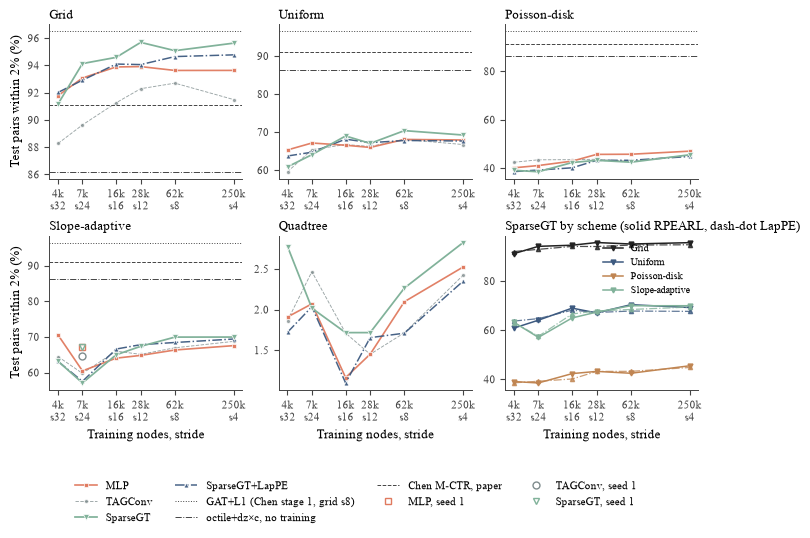

In [6]:
plot_transfer('test_acc2', 'Test pairs within 2% (%)', refs=REFS_ACC2, fname='e34_transfer_acc2')

## 2. Sample paths: models trained on the smallest and the largest grid

Pairs: the detour ratio is the true length over the octile+dz length, the shortest path on a flat 8-neighbour grid
with the height difference added. A ratio of 1 means the route is the straight grid route; above 1 it bends around terrain.
Measuring against the 3D straight line instead picks grid artefacts (octile factor up to 1.08), not terrain.
For each test source I take the target 6–14 km away with the largest ratio, then the three sources with the largest such ratio.
The true path comes from Dijkstra on the test graph.

In [7]:
import sys, torch, yaml
sys.path.insert(0, str(REPO))
from spnn.models.factory import configure_embedding_module

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
test = np.load(TEST)
X = test['node_features']
N = len(X)
SIDE = int(round(np.sqrt(N)))                       # 500 x 500, x varies fastest
Z = X[:, 2].reshape(SIDE, SIDE)
EXTENT = [X[:, 0].min(), X[:, 0].max(), X[:, 1].min(), X[:, 1].max()]
ei, w = test['edge_index'], test['distances']
G = sp.csr_matrix((w, (ei[0], ei[1])), shape=(N, N))

srcs, tars, lengths = test['srcs'], test['tars'], test['lengths']
euclid = np.linalg.norm(X[srcs] - X[tars], axis=1)
dxy = np.abs(X[srcs, :2] - X[tars, :2])
octile = dxy.max(1) + (np.sqrt(2) - 1) * dxy.min(1)
octile_dz = np.sqrt(octile ** 2 + (X[srcs, 2] - X[tars, 2]) ** 2)
detour = np.where(octile_dz > 0, lengths / np.maximum(octile_dz, 1e-9), 1.0)
pairs = pd.DataFrame(dict(src=srcs, tar=tars, length=lengths, euclid=euclid, detour=detour))
cand = pairs[(pairs.length > 6) & (pairs.length < 14)]
best = cand.loc[cand.groupby('src').detour.idxmax()].sort_values('detour', ascending=False)
PATH_PAIRS = best.head(3).reset_index(drop=True)
PATH_PAIRS

,src,tar,length,euclid,detour
0,247792,185417,7.902588,7.075831,1.116842
1,137059,232559,8.449612,7.644498,1.105319
2,158393,228386,6.308701,5.612259,1.102679


In [8]:
MODEL_SPEC = {
    'mlp':     ('MLP',      'configs/e31-mlp.yml'),
    'tagconv': ('TAGConv',  'configs/e31-tagconv.yml'),
    'sgt2':    ('SparseGT', 'configs/e32-sparse-gt-k2.yml'),
    'sgt2lap': ('SparseGT', 'configs/e35-sparse-gt-k2-lappe.yml'),   # embedding_mode lappe, lappe_k 64
}
from spnn.graphs.spectral import laplacian_pe

def run_dir(scheme, stride, model):
    return (E35 if model == 'sgt2lap' else RUNS) / f'norway_{scheme}_s{stride:02d}_{model}'

def embeddings(scheme, stride, model):
    # Node embeddings of the test graph from a trained run; cached as float16.
    path = CACHE / f'emb_{scheme}_s{stride:02d}_{model}.npy'
    if path.exists():
        return np.load(path).astype(np.float32)
    layer_type, cfg_path = MODEL_SPEC[model]
    cfg = next(iter(yaml.safe_load(open(REPO / cfg_path)).values()))
    if layer_type == 'SparseGT':
        cfg['gnn'].setdefault('sparse_gt', {}).setdefault('embedding_mode', 'data')
    net = configure_embedding_module(cfg['gnn'], layer_type, edge_dim=1, new=True)
    weights = next(run_dir(scheme, stride, model).glob('models/**/final_model.pt'))
    net.load_state_dict(torch.load(weights, map_location='cpu'))
    net = net.to(DEVICE).eval()
    x = torch.tensor(X, dtype=torch.float, device=DEVICE)
    if getattr(net, 'embedding_mode', None) == 'lappe':   # the test graph's own eigenvectors, from the cache
        V, _ = laplacian_pe(N, ei, net.lappe_k, cache_dir=LAPPE)
        x = torch.cat([x, torch.from_numpy(V).to(DEVICE)], dim=1)
    with torch.no_grad():
        if layer_type == 'MLP':
            e = net(x)
        else:
            e = net(x, torch.tensor(ei, dtype=torch.long, device=DEVICE),
                    edge_attr=torch.tensor(w, dtype=torch.float, device=DEVICE).unsqueeze(-1))
    e = e.cpu().numpy()
    np.save(path, e.astype(np.float16))
    del net; torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    return e

def true_path(s, t):
    dist, pred = dijkstra(G, indices=s, return_predecessors=True)
    path = [t]
    while path[-1] != s:
        path.append(pred[path[-1]])
    return path[::-1], dist[t]

def greedy_path(E, s, t, max_steps=20000):
    # Step to the unvisited neighbour j that minimises w_ij + d_hat(j, t), with d_hat the L1 embedding distance.
    h = np.abs(E - E[t]).sum(1)
    path, seen, i = [s], {s}, s
    while i != t and len(path) < max_steps:
        nb = G.indices[G.indptr[i]:G.indptr[i + 1]]
        wt = G.data[G.indptr[i]:G.indptr[i + 1]]
        ok = np.array([j not in seen for j in nb])
        if not ok.any():
            break                                     # dead end: report as unfinished
        nb, wt = nb[ok], wt[ok]
        i = int(nb[np.argmin(wt + h[nb])])
        path.append(i); seen.add(i)
    length = sum(G[a, b] for a, b in zip(path[:-1], path[1:]))
    return path, length, i == t, h[s]

PATH_STRIDES = [32, 4]
path_cache = CACHE / 'paths_grid_v2.json'
PATHS = json.load(open(path_cache)) if path_cache.exists() else {}
changed = False
for k, r in PATH_PAIRS.iterrows():
    if f'{k}/true' not in PATHS:
        tp, tl = true_path(int(r.src), int(r.tar))
        PATHS[f'{k}/true'] = dict(path=[int(v) for v in tp], length=float(tl)); changed = True
for stride in PATH_STRIDES:
    for model in MODELS:        # missing (model, stride) entries are computed and added to the cache
        if all(f'{k}/{model}/s{stride}' in PATHS for k, _ in PATH_PAIRS.iterrows()):
            continue
        if not any(run_dir('grid', stride, model).glob('models/**/final_model.pt')):
            print(f'no run yet: grid s{stride} {model}'); continue
        E = embeddings('grid', stride, model)
        for k, r in PATH_PAIRS.iterrows():
            p, L, done, dhat = greedy_path(E, int(r.src), int(r.tar))
            PATHS[f'{k}/{model}/s{stride}'] = dict(path=[int(v) for v in p], length=float(L),
                                                    reached=bool(done), pred=float(dhat))
        changed = True
if changed:
    json.dump(PATHS, open(path_cache, 'w'))
PATH_MODELS = [m for m in MODELS if all(f'{k}/{m}/s{s}' in PATHS for k, _ in PATH_PAIRS.iterrows() for s in PATH_STRIDES)]

tab = []
for k, r in PATH_PAIRS.iterrows():
    T = PATHS[f'{k}/true']['length']
    for stride in PATH_STRIDES:
        for model in PATH_MODELS:
            q = PATHS[f'{k}/{model}/s{stride}']
            tab.append(dict(pair=k, train=f'grid s{stride}', model=MODEL_NAMES[model], true_km=round(T, 3),
                            predicted_km=round(q['pred'], 3), pred_err_pct=round(100 * (q['pred'] - T) / T, 2),
                            greedy_km=round(q['length'], 3), greedy_excess_pct=round(100 * (q['length'] - T) / T, 2),
                            reached=q['reached']))
pd.DataFrame(tab)

,pair,train,model,true_km,predicted_km,pred_err_pct,greedy_km,greedy_excess_pct,reached
0,0,grid s32,MLP,7.903,7.376,-6.66,8.066,2.07,True
1,0,grid s32,TAGConv,7.903,7.493,-5.18,9.831,24.40,True
2,0,grid s32,SparseGT,7.903,7.361,-6.85,8.197,3.73,True
3,0,grid s32,SparseGT+LapPE,7.903,7.328,-7.27,8.164,3.31,True
4,0,grid s4,MLP,7.903,7.587,-3.99,8.087,2.33,True
5,0,grid s4,TAGConv,7.903,7.613,-3.66,8.070,2.12,True
6,0,grid s4,SparseGT,7.903,7.601,-3.82,8.109,2.61,True
7,0,grid s4,SparseGT+LapPE,7.903,7.508,-4.99,8.026,1.56,True
8,1,grid s32,MLP,8.450,8.169,-3.32,8.497,0.56,True
9,1,grid s32,TAGConv,8.450,8.220,-2.71,8.476,0.32,True


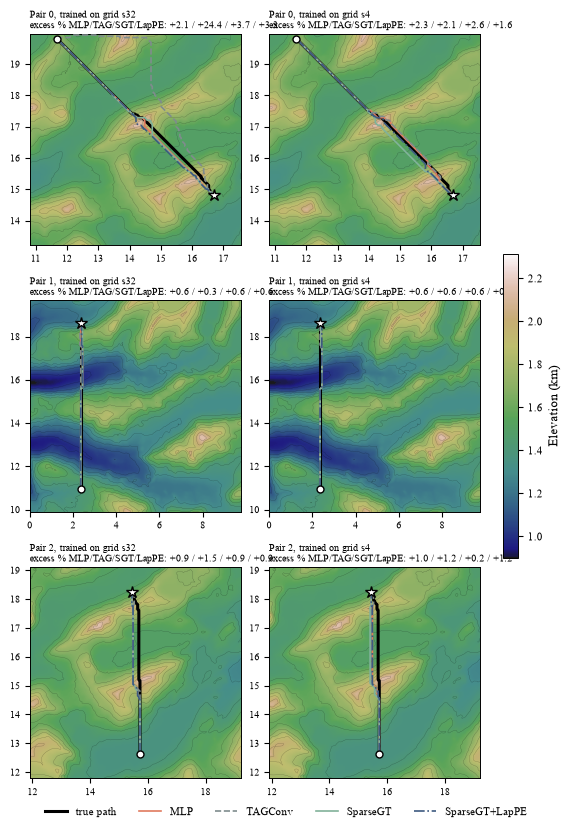

In [9]:
def plot_paths(fname='e34_paths_grid'):
    fig, axes = plt.subplots(len(PATH_PAIRS), len(PATH_STRIDES), figsize=(5.6, 8.0), constrained_layout=True)
    for k, r in PATH_PAIRS.iterrows():
        tp = np.array(PATHS[f'{k}/true']['path'])
        allpts = [tp] + [np.array(PATHS[f'{k}/{m}/s{s}']['path']) for m in PATH_MODELS for s in PATH_STRIDES]
        allpts = np.concatenate(allpts)
        x0, x1 = X[allpts, 0].min(), X[allpts, 0].max()
        y0, y1 = X[allpts, 1].min(), X[allpts, 1].max()
        half = 0.6 * max(x1 - x0, y1 - y0) + 0.3
        half = min(half, (EXTENT[1] - EXTENT[0]) / 2)
        cx = np.clip((x0 + x1) / 2, EXTENT[0] + half, EXTENT[1] - half)   # keep the window on the terrain
        cy = np.clip((y0 + y1) / 2, EXTENT[2] + half, EXTENT[3] - half)
        for c, stride in enumerate(PATH_STRIDES):
            ax = axes[k, c]
            im = ax.imshow(Z, origin='lower', extent=EXTENT, cmap='gist_earth', alpha=0.9)
            ax.contour(Z, levels=15, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            ax.plot(X[tp, 0], X[tp, 1], color='k', lw=2.2, label='true path', zorder=4)
            for model in PATH_MODELS:
                q = PATHS[f'{k}/{model}/s{stride}']
                p = np.array(q['path'])
                ax.plot(X[p, 0], X[p, 1], color=PALETTE[model], lw=1.2,
                        ls={'tagconv': '--', 'sgt2lap': '-.'}.get(model, '-'), zorder=5,
                        label=f"{MODEL_NAMES[model]}")
            ax.plot(*X[int(r.src), :2], 'o', color='white', mec='k', ms=5, zorder=6)
            ax.plot(*X[int(r.tar), :2], '*', color='white', mec='k', ms=9, zorder=6)
            ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
            ax.set_aspect('equal')
            ex = ' / '.join(f"{100 * (PATHS[f'{k}/{m}/s{stride}']['length'] / PATHS[f'{k}/true']['length'] - 1):+.1f}"
                            for m in PATH_MODELS)
            ax.set_title(f"Pair {k}, trained on grid s{stride}\nexcess % {'/'.join(SHORT[m] for m in PATH_MODELS)}: {ex}", fontsize=7)
            ax.tick_params(labelsize=7)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.03))
    fig.colorbar(im, ax=axes, shrink=0.4, label='Elevation (km)')
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_paths()

## 3. Error heatmaps for one hard source

The source is the test source whose paths bend most: the largest mean detour ratio (true / octile+dz, as in section 2)
over targets more than 2 km away.
Each panel shows the signed relative error $(\hat d - d)/d$ of a model for every node of the test terrain as target.
Red means the model overestimates the distance, blue that it underestimates.

In [10]:
far = pairs[pairs.euclid > 2]
src_detour = far.groupby('src').detour.mean().sort_values(ascending=False)
HARD_SRC = int(src_detour.index[0])
print('mean detour per source (targets > 2 km):'); print(src_detour.round(4).to_string())
print('hard source', HARD_SRC, 'at', X[HARD_SRC].round(2))

def rel_error_map(scheme, stride, model, src=HARD_SRC):
    path = CACHE / f'heat_{scheme}_s{stride:02d}_{model}_src{src}.npy'
    if path.exists():
        return np.load(path)
    f = next(run_dir(scheme, stride, model).glob('models/**/preds.csv.gz'))
    df = pd.read_csv(f, usecols=['srcs', 'tars', 'preds', 'lengths'])
    df = df[df.srcs.astype(int) == src]
    m = np.full(N, np.nan, dtype=np.float32)
    ok = df.lengths.values > 0
    m[df.tars.values[ok].astype(int)] = (df.preds.values[ok] - df.lengths.values[ok]) / df.lengths.values[ok]
    np.save(path, m)
    return m

true_d = dijkstra(G, indices=HARD_SRC)

mean detour per source (targets > 2 km):
src
239655    1.0356
174202    1.0338
33603     1.0250
210330    1.0249
247792    1.0248
9063      1.0227
42546     1.0214
27034     1.0212
137059    1.0211
158393    1.0196
hard source 239655 at [ 6.2  19.17  1.83]


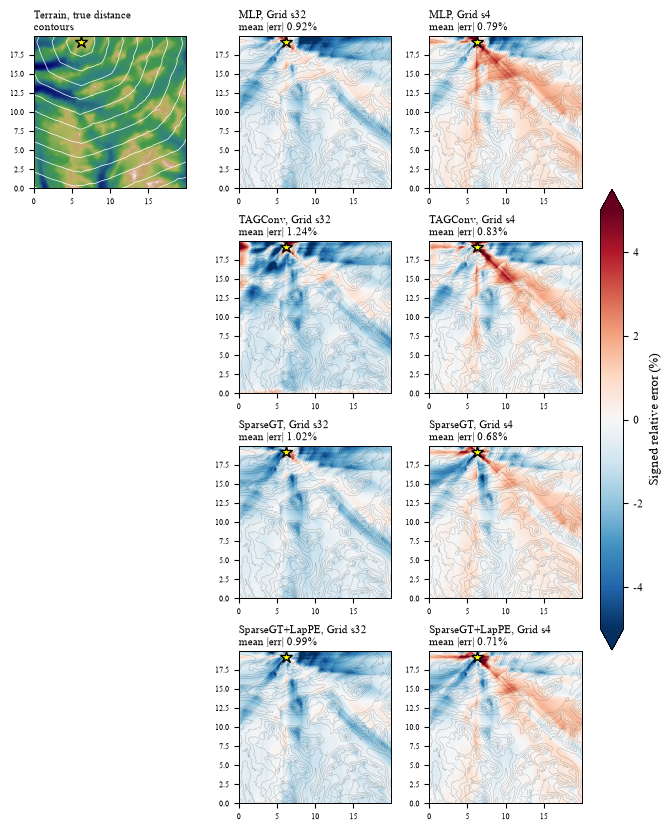

In [11]:
def plot_heatmaps(scheme='grid', strides=(32, 4), vmax=5.0, fname=None):
    models = [m for m in MODELS if all(any(run_dir(scheme, s, m).glob('models/**/preds.csv.gz')) for s in strides)]
    fig, axes = plt.subplots(len(models), len(strides) + 1, figsize=(2.0 * (len(strides) + 1) + 0.6, 2.05 * len(models)),
                             constrained_layout=True)
    for r, model in enumerate(models):
        ax = axes[r, 0]
        if r == 0:
            ax.imshow(Z, origin='lower', extent=EXTENT, cmap='gist_earth')
            ax.contour(true_d.reshape(SIDE, SIDE), levels=12, origin='lower', extent=EXTENT, colors='w', linewidths=0.5)
            ax.set_title('Terrain, true distance\ncontours', fontsize=8)
        else:
            ax.axis('off')
        for c, stride in enumerate(strides, start=1):
            ax = axes[r, c]
            m = 100 * rel_error_map(scheme, stride, model)
            im = ax.imshow(m.reshape(SIDE, SIDE), origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            ax.contour(Z, levels=10, origin='lower', extent=EXTENT, colors='k', linewidths=0.2, alpha=0.4)
            ax.set_title(f'{MODEL_NAMES[model]}, {SCHEME_TITLES[scheme]} s{stride}\n'
                         f'mean |err| {np.nanmean(np.abs(m)):.2f}%', fontsize=8)
        for c in range(len(strides) + 1):
            if r > 0 and c == 0:
                continue
            axes[r, c].plot(*X[HARD_SRC, :2], '*', color='yellow', mec='k', ms=9)
            axes[r, c].tick_params(labelsize=6)
    fig.colorbar(im, ax=axes[:, 1:], shrink=0.6, label='Signed relative error (%)', extend='both')
    if fname:
        fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_heatmaps('grid', fname='e34_heatmap_grid')

The same source for models trained on the uniform scheme. This shows where the isotropic kNN metric of the training
graph departs from the octile metric of the grid test graph (finding 2 of the e34 summary).

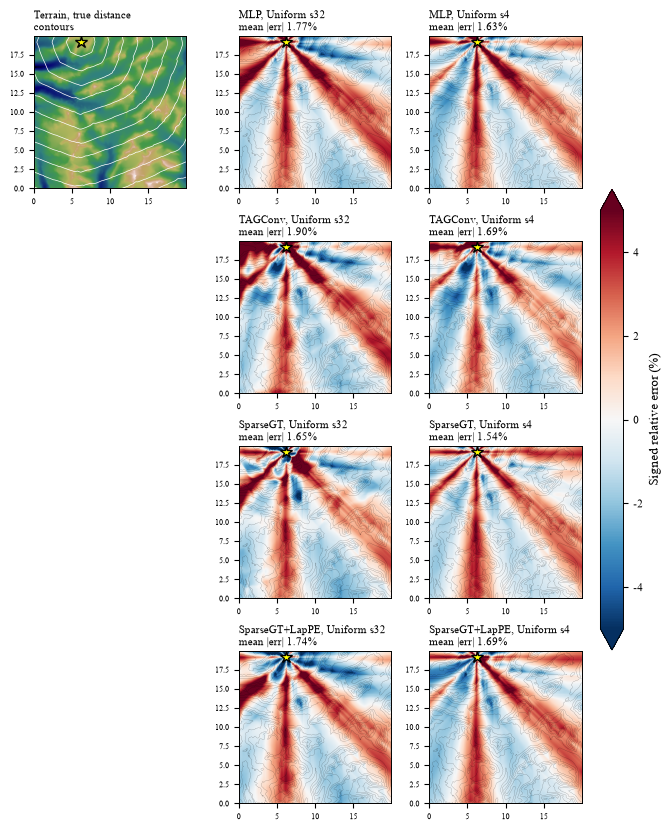

In [12]:
plot_heatmaps('uniform', strides=(32, 4), fname='e34_heatmap_uniform')

### 3.1 Are the rays a straight-line bias?

The error maps above have a directional structure on every training graph. One explanation would be a model that
predicts something close to the straight-line distance, which underestimates wherever the true path bends. To test
it, for every source $s$ of the grid test I regress the error $\hat d - d$ on the straight-line bias $e - d$, with
$e$ the 3D Euclidean distance, and on $o - d$, with $o$ the octile+dz route of section 2. The slope $\beta$ is the
weight of the straight-line estimate in the prediction (1: pure straight line, 0: none). $R^2$ is the share of the
error variance that the bias explains. The angle and distance columns are the share of the relative-error variance
explained by 5° angle bins and 1 km distance bins around the source. Targets within 0.5 km of the source are skipped.
The models' predictions on the test sets come from the e34c cross evaluation (`scripts/e34c_eval_cross.py`).
Values are means over the 10 sources, 250k targets each; the own-test rows use each scheme's matched test set.

In [13]:
E34C = Path(os.environ.get('E34C', '~/runs/e34c')).expanduser()
TESTDIR = Path(os.environ.get('E34C_TESTS', '~/data/spnn/e34c')).expanduser()

def straight_line_fit(err, x):
    A = np.c_[np.ones_like(x), x]
    coef, *_ = np.linalg.lstsq(A, err, rcond=None)
    return coef[1], 1 - (err - A @ coef).var() / err.var()

def var_share(rel, groups):
    return pd.Series(rel).groupby(groups).transform('mean').var() / rel.var()

def straight_line_rows(test_name, t, pred, label):
    rows = []
    for s in np.unique(t['srcs']):
        sel = (t['srcs'] == s) & (t['d'] > 0.5)
        d, e, o, p = t['d'][sel], t['e'][sel], t['o'][sel], pred[sel]
        err, rel = p - d, (p - d) / d
        be, r2e = straight_line_fit(err, e - d)
        bo, r2o = straight_line_fit(err, o - d)
        dx = t['X'][t['tars'][sel], :2] - t['X'][s, :2]
        abin = np.floor(np.degrees(np.arctan2(dx[:, 1], dx[:, 0])) / 5).astype(int)
        rows.append(dict(label=label, test=test_name, src=int(s), nmae=100 * np.abs(rel).mean(), bias=100 * rel.mean(),
                         beta_e=be, r2_e=r2e, beta_o=bo, r2_o=r2o,
                         angle_share=var_share(rel, abin), dist_share=var_share(rel, np.floor(d).astype(int))))
    return rows

def load_test_pairs(name):
    f = TEST if name == 'grid' else TESTDIR / f'norway_{name}_test-004.npz'
    d = np.load(f); Xt = d['node_features']; s_, t_ = d['srcs'], d['tars']
    dxy = np.abs(Xt[s_, :2] - Xt[t_, :2])
    oct_ = dxy.max(1) + (np.sqrt(2) - 1) * dxy.min(1)
    return dict(X=Xt, srcs=s_, tars=t_, d=d['lengths'], e=np.linalg.norm(Xt[s_] - Xt[t_], axis=1),
                o=np.sqrt(oct_ ** 2 + (Xt[s_, 2] - Xt[t_, 2]) ** 2))

STATS_CSV = CACHE / 'straight_line_stats.csv'
if STATS_CSV.exists():
    sl = pd.read_csv(STATS_CSV)
else:
    rows, tests = [], {}
    for stride in (32, 4):
        for scheme in SCHEMES:
            for model in MODELS:
                for test_name in ('grid', scheme):
                    f = E34C / 'preds' / f'norway_{scheme}_s{stride:02d}_{model}__{test_name}.npy'
                    if not f.exists():
                        continue
                    if test_name not in tests:
                        tests[test_name] = load_test_pairs(test_name)
                    rows += straight_line_rows(test_name, tests[test_name], np.load(f).astype(np.float64),
                                               f'{scheme} s{stride} {model}')
    sl = pd.DataFrame(rows); sl.to_csv(STATS_CSV, index=False)

sl['own_test'] = sl.test == sl.label.str.split().str[0]
agg = sl.groupby(['label', 'test', 'own_test']).mean(numeric_only=True).drop(columns='src').reset_index()
print('Straight-line fits of the grid-trained models on the grid test (means over 10 sources):')
agg[agg.label.str.startswith('grid')].set_index('label')[['nmae', 'bias', 'beta_e', 'r2_e', 'beta_o', 'r2_o', 'angle_share', 'dist_share']].round(3)

Straight-line fits of the grid-trained models on the grid test (means over 10 sources):


,nmae,bias,beta_e,r2_e,beta_o,r2_o,angle_share,dist_share
label,,,,,,,,
grid s32 mlp,0.822,-0.620,0.053,0.075,0.346,0.500,0.585,0.120
grid s32 sgt2,0.871,-0.758,0.053,0.088,0.326,0.511,0.545,0.086
grid s32 sgt2lap,0.824,-0.632,0.044,0.059,0.308,0.435,0.551,0.092
grid s32 tagconv,1.025,-0.549,0.068,0.091,0.341,0.364,0.497,0.168
grid s4 mlp,0.707,0.052,0.012,0.016,0.131,0.106,0.561,0.117
grid s4 sgt2,0.612,-0.051,0.005,0.007,0.082,0.067,0.519,0.102
grid s4 sgt2lap,0.680,-0.117,0.022,0.025,0.090,0.078,0.536,0.084
grid s4 tagconv,0.811,0.091,0.041,0.054,0.165,0.128,0.484,0.089


In [14]:
print('Each scheme\'s models on their own matched test:')
agg[agg.own_test & (agg.label.str.contains(' s4 '))].set_index('label')[['nmae', 'bias', 'beta_e', 'r2_e', 'beta_o', 'r2_o', 'angle_share', 'dist_share']].round(3)

Each scheme's models on their own matched test:


,nmae,bias,beta_e,r2_e,beta_o,r2_o,angle_share,dist_share
label,,,,,,,,
grid s4 mlp,0.707,0.052,0.012,0.016,0.131,0.106,0.561,0.117
grid s4 sgt2,0.612,-0.051,0.005,0.007,0.082,0.067,0.519,0.102
grid s4 sgt2lap,0.680,-0.117,0.022,0.025,0.090,0.078,0.536,0.084
grid s4 tagconv,0.811,0.091,0.041,0.054,0.165,0.128,0.484,0.089
poisson-disk s4 mlp,0.846,0.074,0.087,0.102,0.077,0.084,0.541,0.106
poisson-disk s4 sgt2,0.651,-0.095,0.015,0.011,0.047,0.053,0.516,0.120
poisson-disk s4 sgt2lap,0.745,-0.053,0.019,0.019,0.060,0.059,0.528,0.121
poisson-disk s4 tagconv,0.868,0.010,0.105,0.129,0.075,0.086,0.394,0.119
quadtree s4 mlp,0.581,0.034,-0.000,0.070,0.000,0.072,0.492,0.216


For comparison, the straight-line estimates themselves on the grid test have nmae 7.3% (Euclid) and 2.4% (octile+dz),
and an angle share of 0.84. The figure shows the hard source. Row 1: the true distance field and the two straight-line
fields, on one colour scale, plus the Euclid bias. Row 2: the predicted distance field of four models on the same scale,
with the true 2 km contours dashed in black. Row 3: their error maps with the fitted Euclid weight.

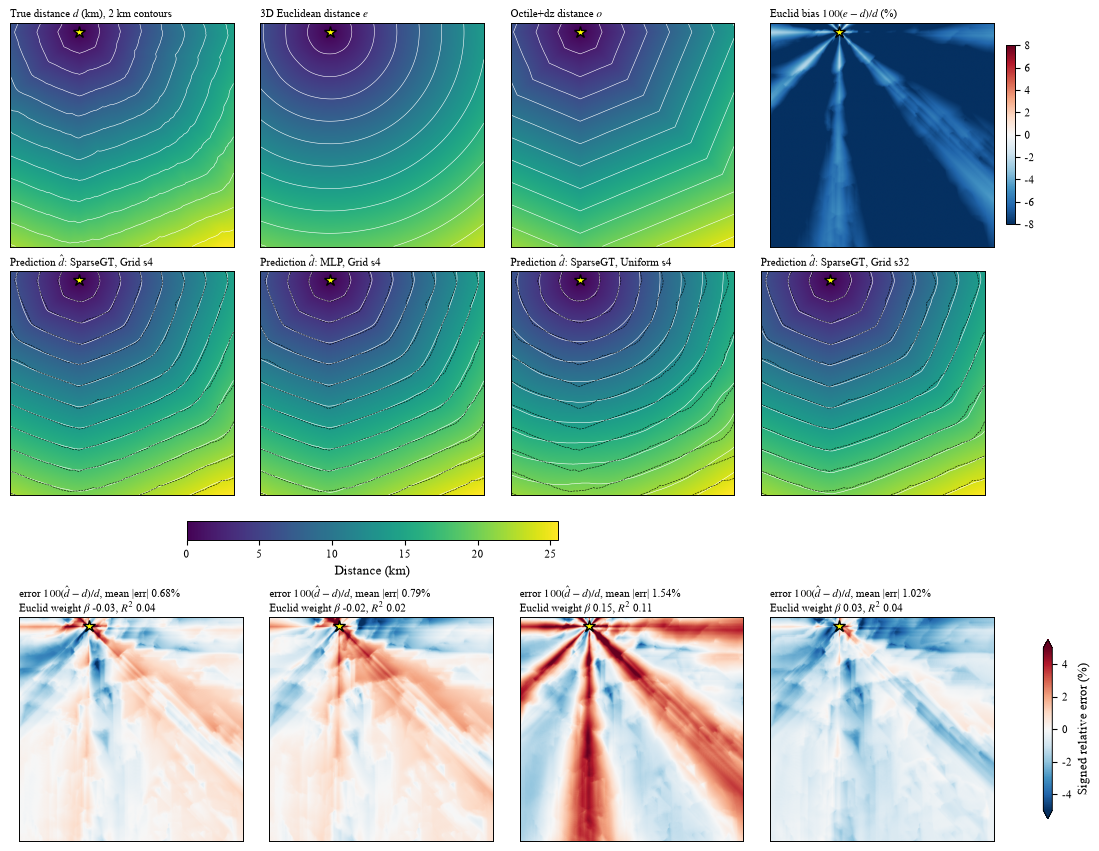

In [15]:
def pair_field(t, s, values):
    m = np.full(N, np.nan); sel = t['srcs'] == s; m[t['tars'][sel]] = values[sel]
    return m.reshape(SIDE, SIDE)

def plot_straight_line_check(src=HARD_SRC, fname='e34_straight_line_check'):
    t = load_test_pairs('grid')
    D, E, O = pair_field(t, src, t['d']), pair_field(t, src, t['e']), pair_field(t, src, t['o'])
    runs = [('grid', 4, 'sgt2'), ('grid', 4, 'mlp'), ('uniform', 4, 'sgt2'), ('grid', 32, 'sgt2')]
    levels = np.arange(2, 30, 2)
    vmax = np.nanmax(D)
    def dist_panel(ax, F, title):
        im = ax.imshow(F, origin='lower', extent=EXTENT, cmap='viridis', vmin=0, vmax=vmax)
        ax.contour(F, levels=levels, origin='lower', extent=EXTENT, colors='w', linewidths=0.4)
        ax.set_title(title, fontsize=8)
        return im
    with np.errstate(invalid='ignore'):
        fig, axes = plt.subplots(3, 4, figsize=(11, 8.4), constrained_layout=True)
        # row 0: the true field, the two straight-line fields, the Euclid bias
        imd = dist_panel(axes[0, 0], D, 'True distance $d$ (km), 2 km contours')
        dist_panel(axes[0, 1], E, '3D Euclidean distance $e$')
        dist_panel(axes[0, 2], O, 'Octile+dz distance $o$')
        imb = axes[0, 3].imshow(100 * (E - D) / D, origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-8, vmax=8)
        axes[0, 3].set_title('Euclid bias $100(e-d)/d$ (%)', fontsize=8)
        fig.colorbar(imb, ax=axes[0, 3], shrink=0.8)
        # row 1: the predicted fields; row 2: their errors
        for c, (scheme, stride, model) in enumerate(runs):
            pred = np.load(E34C / 'preds' / f'norway_{scheme}_s{stride:02d}_{model}__grid.npy').astype(np.float64)
            P = pair_field(t, src, pred)
            dist_panel(axes[1, c], P, f'Prediction $\\hat d$: {MODEL_NAMES[model]}, {SCHEME_TITLES[scheme]} s{stride}')
            axes[1, c].contour(D, levels=levels, origin='lower', extent=EXTENT, colors='k', linewidths=0.4, linestyles='--')
            sel = (t['srcs'] == src) & (t['d'] > 0.5)
            be, r2 = straight_line_fit(pred[sel] - t['d'][sel], t['e'][sel] - t['d'][sel])
            ERR = 100 * (P - D) / D
            ime = axes[2, c].imshow(ERR, origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-5, vmax=5)
            axes[2, c].set_title(f'error $100(\\hat d-d)/d$, mean |err| {np.nanmean(np.abs(ERR)):.2f}%\nEuclid weight $\\beta$ {be:.2f}, $R^2$ {r2:.2f}', fontsize=8)
        for ax in axes.ravel():
            ax.plot(*X[src, :2], '*', color='yellow', mec='k', ms=9)
            ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(imd, ax=axes[:2, :3], shrink=0.5, label='Distance (km)', location='bottom')
        fig.colorbar(ime, ax=axes[2], shrink=0.8, label='Signed relative error (%)', extend='both')
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_straight_line_check()

Euclid bias and model error side by side, on one colour scale, for the same source. Below: the mean relative error
per 5° direction bin around the source, for the straight-line estimates and the models, and the model error against
the Euclid bias target by target, with the fitted line of slope $\beta$.

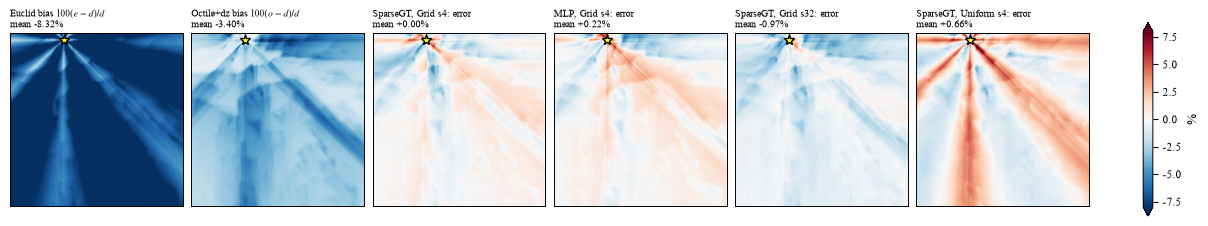

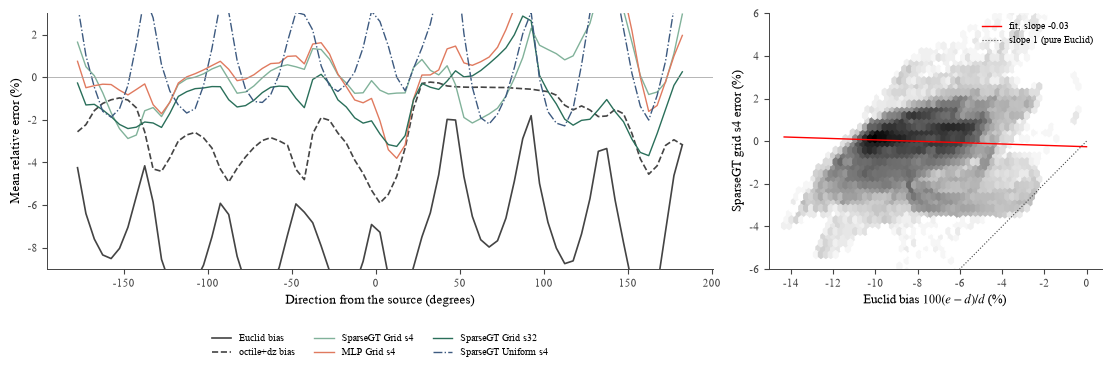

,model,corr_euclid_profile,corr_octile_profile
0,SparseGT grid s4,0.34,0.11
1,MLP grid s4,0.50,0.54
2,SparseGT grid s32,0.52,0.54
3,SparseGT uniform s4,0.78,-0.06


In [16]:
def plot_bias_comparison(src=HARD_SRC, vmax=8.0, fname='e34_bias_vs_euclid'):
    t = load_test_pairs('grid')
    sel = (t['srcs'] == src) & (t['d'] > 0.5)
    d, e, o = t['d'][sel], t['e'][sel], t['o'][sel]
    dx = t['X'][t['tars'][sel], :2] - t['X'][src, :2]
    abin = np.floor(np.degrees(np.arctan2(dx[:, 1], dx[:, 0])) / 5).astype(int)
    bins = np.sort(np.unique(abin)); centres = bins * 5 + 2.5
    def profile(rel):
        return pd.Series(rel).groupby(abin).mean().reindex(bins).values
    runs = [('grid', 4, 'sgt2'), ('grid', 4, 'mlp'), ('grid', 32, 'sgt2'), ('uniform', 4, 'sgt2')]
    colors = [PALETTE['sgt2'], PALETTE['mlp'], '#2a6f5a', PALETTE['sgt2lap']]
    preds = {r: np.load(E34C / 'preds' / f'norway_{r[0]}_s{r[1]:02d}_{r[2]}__grid.npy').astype(np.float64) for r in runs}
    D = pair_field(t, src, t['d'])
    # maps on one colour scale
    with np.errstate(invalid='ignore'):
        maps = [('Euclid bias $100(e-d)/d$', 100 * (pair_field(t, src, t['e']) - D) / D),
                ('Octile+dz bias $100(o-d)/d$', 100 * (pair_field(t, src, t['o']) - D) / D)] + \
               [(f'{MODEL_NAMES[m]}, {SCHEME_TITLES[sc]} s{st}: error', 100 * (pair_field(t, src, preds[(sc, st, m)]) - D) / D)
                for sc, st, m in runs]
    fig, axes = plt.subplots(1, 6, figsize=(12, 2.5), constrained_layout=True)
    for ax, (title, M) in zip(axes, maps):
        im = ax.imshow(M, origin='lower', extent=EXTENT, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        ax.plot(*X[src, :2], '*', color='yellow', mec='k', ms=8)
        ax.set_title(f'{title}\nmean {np.nanmean(M):+.2f}%', fontsize=7); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.8, label='%', extend='both')
    fig.savefig(FIGS / f'{fname}_maps.pdf', bbox_inches='tight')
    plt.show()
    # direction profiles and the scatter
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), width_ratios=[2, 1], constrained_layout=True)
    pe, po = profile(100 * (e - d) / d), profile(100 * (o - d) / d)
    ax.plot(centres, pe, color='#444', lw=1.2, label='Euclid bias')
    ax.plot(centres, po, color='#444', lw=1.2, ls='--', label='octile+dz bias')
    corr = {}
    for (sc, st, m), c in zip(runs, colors):
        pm = profile(100 * (preds[(sc, st, m)][sel] - d) / d)
        corr[(sc, st, m)] = (np.corrcoef(pm, pe)[0, 1], np.corrcoef(pm, po)[0, 1])
        ax.plot(centres, pm, color=c, lw=1.0, ls='-' if sc == 'grid' else '-.', label=f'{MODEL_NAMES[m]} {SCHEME_TITLES[sc]} s{st}')
    ax.axhline(0, color='#999', lw=0.5)
    ax.set_xlabel('Direction from the source (degrees)'); ax.set_ylabel('Mean relative error (%)')
    ax.set_ylim(-9, 3); ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.22)); clean_axes(ax)
    sc, st, m = runs[0]
    err = 100 * (preds[(sc, st, m)][sel] - d) / d; bias = 100 * (e - d) / d
    ax2.hexbin(bias, err, gridsize=60, bins='log', cmap='Greys', mincnt=1)
    be, r2 = straight_line_fit(preds[(sc, st, m)][sel] - d, e - d)
    xs = np.array([bias.min(), 0]); ax2.plot(xs, be * xs + np.mean(err - be * bias), color='r', lw=1, label=f'fit, slope {be:.2f}')
    ax2.plot(xs, xs, color='#444', lw=0.8, ls=':', label='slope 1 (pure Euclid)')
    ax2.set_xlabel('Euclid bias $100(e-d)/d$ (%)'); ax2.set_ylabel(f'{MODEL_NAMES[m]} grid s{st} error (%)')
    ax2.set_ylim(-6, 6); ax2.legend(frameon=False, fontsize=7); clean_axes(ax2)
    fig.savefig(FIGS / f'{fname}_profiles.pdf', bbox_inches='tight')
    plt.show()
    return pd.DataFrame([dict(model=f'{MODEL_NAMES[m]} {sc} s{st}', corr_euclid_profile=v[0], corr_octile_profile=v[1])
                         for (sc, st, m), v in corr.items()]).round(2)

plot_bias_comparison()

Reading:
- **No straight-line collapse.** The Euclid weight $\beta$ is below 0.07 and $R^2$ below 0.1 for every grid-trained
  model, and below 0.05 for every scheme's SparseGT on its own test. The scatter shows it directly: the model error
  does not grow with the Euclid bias, the fitted slope is −0.03 against 1 for a straight-line predictor.
- **Scale.** On one colour scale the Euclid bias map is saturated at −8% while the model maps are within ±2%. The
  prediction fields look concentric because the true field does: the terrain detours are at most a few percent of
  the distance, so every field in the figure is an octagon-shaped bowl at this scale. The difference lives in the
  error maps.
- **The coarse grid models carry a grid-route bias.** At stride 32 the octile+dz bias explains half of the error
  variance ($\beta_o$ 0.3, $R^2$ 0.4–0.5, mean bias −0.6 to −0.8%), and the direction profile of SparseGT s32
  correlates 0.54 with the octile+dz profile. At stride 4 that share is below 0.13 and the correlation 0.11.
- **The errors are directional, but not along straight lines.** Angle bins explain about half of the relative-error
  variance, distance bins about a tenth. The direction profile of the Euclid bias has dips every 45°, the octile
  artefact of the grid test. The uniform model's error on the grid test has the same 45° pattern with the opposite
  sign (profile correlation 0.78 with the Euclid profile), which is the metric mismatch of e34c section 3.1. The grid
  models do not have it.
- A likely source of the rays that remain: every target behind a pass shares the path to that pass, so an error on
  that segment is inherited by the whole sector behind it on any graph. This is not tested here.

## 4. Cost of the Laplacian eigenvectors (e35)

RPEARL learns its encodings inside the model. LapPE needs the k lowest eigenvectors of the normalised Laplacian of
every graph the model sees, train and test. `spnn.graphs.spectral` computes them with ARPACK (`eigsh`, tol 1e-6) and
records the wall time, the peak RSS and per-k timings in the cache sidecar. The timings below are from plaza
(48 threads) with GPU training jobs sharing the CPU, so they are an upper bound of the idle-machine time by about 2×.
The 250k-node test grid is the same graph as the stride-4 grid training set and appears once.

In [17]:
rows = []
for f in sorted(LAPPE.glob('lappe_*.json')):
    d = json.load(open(f))
    srcs = [Path(s).name for s in d.get('sources', [])]
    names = [s for s in srcs if s.startswith('norway_')]
    m = next((re.match(r'norway_(.+?)_(s\d\d|test-004)\.npz', s) for s in names if re.match(r'norway_(.+?)_(s\d\d|test-004)\.npz', s)), None)
    scheme = m[1] if m else ('grid' if any(s.startswith('full_test') for s in srcs) else '?')
    row = dict(key=d['key'], scheme=scheme, sources=', '.join(srcs), n=d['n'], edges=d['undirected_edges'],
               seconds_64=d['seconds'], peak_rss_gb=d['peak_rss_gb'], host=d['host'],
               lambda2=d['eigenvalues'][1], gap_23=d['eigenvalues'][2] - d['eigenvalues'][1],
               gap_2_1=d['eigenvalues'][1] - d['eigenvalues'][0])
    for k, t in d.get('timings', {}).items():
        row[f'seconds_k{int(k):02d}'] = t['seconds']
    rows.append(row)
cost = pd.DataFrame(rows).sort_values(['n', 'scheme']).reset_index(drop=True)
cols = ['scheme', 'n', 'edges', 'seconds_64', 'peak_rss_gb'] + sorted(c for c in cost.columns if c.startswith('seconds_k')) + ['lambda2', 'gap_23']
cost[cols].round({'seconds_64': 1, 'peak_rss_gb': 2, 'lambda2': 7, 'gap_23': 8})

,scheme,n,edges,seconds_64,peak_rss_gb,seconds_k02,seconds_k04,seconds_k08,seconds_k16,seconds_k32,seconds_k64,lambda2,gap_23
0,grid,3969,15500,9.8,0.08,0.02,0.02,0.05,0.07,0.11,7.73,0.000956,0.000000e+00
1,poisson-disk,3969,17101,6.4,0.08,0.03,0.03,0.03,0.05,0.10,6.15,0.000991,1.290000e-05
2,slope-adaptive,3969,18608,8.0,0.08,0.04,0.04,0.05,0.07,0.11,7.67,0.000757,3.520000e-05
3,uniform,3969,18342,0.8,0.08,0.04,0.04,0.04,0.06,0.11,8.40,0.000772,1.896000e-05
4,quadtree,3972,7059,10.1,0.07,0.04,0.04,0.07,0.09,0.13,9.08,0.000494,1.264300e-04
5,poisson-disk,7043,30211,10.7,0.09,0.07,0.07,0.09,0.12,1.80,27.74,0.000556,4.250000e-06
6,quadtree,7053,12684,2.9,0.08,0.10,0.09,0.16,0.19,3.14,38.80,0.000273,8.625000e-05
7,grid,7056,27722,2.0,0.08,0.05,0.04,0.10,0.16,1.72,33.55,0.000535,0.000000e+00
8,slope-adaptive,7056,32917,30.1,0.09,0.09,0.09,0.13,0.15,1.79,34.12,0.000420,3.286000e-05
9,uniform,7056,32548,42.4,0.09,0.09,0.08,0.10,0.14,2.26,32.79,0.000437,3.600000e-06


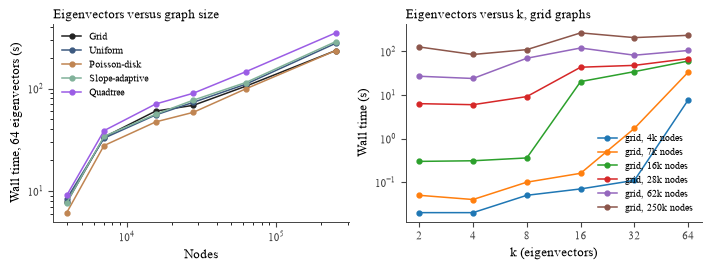

In [18]:
def plot_lappe_cost(fname='e35_lappe_cost'):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), constrained_layout=True)
    ax = axes[0]
    for scheme, c in zip(SCHEMES, ['#222', '#3d5a80', '#c08552', '#81b29a', '#9b5de5']):
        g = cost[cost.scheme == scheme].sort_values('n')
        # the retimed k=64 pass (nice 10, 2026-10-21); `seconds_64` is the noisier first pass with a concurrent eigsh
        ax.plot(g.n, g.seconds_k64, marker='o', ms=3.5, lw=1.1, color=c, label=SCHEME_TITLES[scheme])
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Nodes'); ax.set_ylabel('Wall time, 64 eigenvectors (s)')
    ax.set_title('Eigenvectors versus graph size'); ax.legend(frameon=False, fontsize=7); clean_axes(ax)
    ax = axes[1]
    kcols = sorted(c for c in cost.columns if c.startswith('seconds_k'))
    ks = [int(c[-2:]) for c in kcols]
    for _, g in cost[cost.scheme == 'grid'].sort_values('n').iterrows():
        y = [g[c] for c in kcols]
        if np.isfinite(y).all():
            ax.plot(ks, y, marker='o', ms=3.5, lw=1.1, label=f'grid, {g.n / 1000:.0f}k nodes')
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(ks, [str(k) for k in ks]); ax.minorticks_off()
    ax.set_xlabel('k (eigenvectors)'); ax.set_ylabel('Wall time (s)')
    ax.set_title('Eigenvectors versus k, grid graphs'); ax.legend(frameon=False, fontsize=7); clean_axes(ax)
    fig.savefig(FIGS / f'{fname}.pdf', bbox_inches='tight')
    plt.show()

plot_lappe_cost()

For scale: one SparseGT training run on the stride-4 grid took 5.5 h on an A6000 (e34), so even the 10-minute
eigendecomposition of the 250k-node graph is a small fraction of training. It is, however, a cost RPEARL never
pays, it is paid again for every new test graph, and it grows faster than linearly with the number of nodes
(the irregular kNN graphs cost 2–4× the grid at equal size because their spectrum is less separated).
The last two columns show the spectrum: on the grids λ2 = λ3 to 1e-14 (two axis modes of a square domain), so
the second and third eigenvectors have no fixed meaning across graphs; the irregular graphs break the tie but
by a gap that is still tiny against λ2 itself.